# ***NLP Classification Using the Donors Choose Dataset***



## ***Importing Libraries***

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE


from sklearn.preprocessing import LabelEncoder


import tensorflow as tf
# from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.text import Tokenizer
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression

import os
import re
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display



## ***1. Data Exploration & Preparation***

### ***Loading Dataset***

In [6]:
df = pd.read_csv("/content/drive/MyDrive/ICT Projects Ai & ML/Datasets/Preprocessed_DonorsChoose_dataset.csv")

In [7]:
df.head()

,id,teacher_prefix,school_state,project_grade_category,project_subject_categories,project_subject_subcategories,teacher_number_of_previously_posted_projects,project_is_approved,price,quantity,cleaned_titles,cleaned_essays,cleaned_summary,isdigit_summary
0,p253737,mrs,in,grades_prek_2,literacy_language,esl_literacy,0,0,154.60,23,educational support english learners home,students english learners working english seco...,students_need_opportunities_practice_beginning...,0
1,p258326,mr,fl,grades_6_8,history_civics_health_sports,civics_government_teamsports,7,1,299.00,1,wanted projector hungry learners,students arrive school eager learn polite gene...,students_need_projector_help_viewing_education...,0
2,p182444,ms,az,grades_6_8,health_sports,health_wellness_teamsports,1,0,516.85,22,soccer equipment awesome middle school students,true champions not always ones win guts mia ha...,students_need_shine_guards_athletic_socks_socc...,0
3,p246581,mrs,ky,grades_prek_2,literacy_language_math_science,literacy_mathematics,4,1,232.90,4,techie kindergarteners,work unique school filled esl english second l...,students_need_engage_reading_math_way_inspire_...,0
4,p104768,mrs,tx,grades_prek_2,math_science,mathematics,1,1,67.98,4,interactive math tools,second grade classroom next year made around 2...,students_need_hands_practice_mathematics_fun_p...,0


In [8]:
df.tail()

,id,teacher_prefix,school_state,project_grade_category,project_subject_categories,project_subject_subcategories,teacher_number_of_previously_posted_projects,project_is_approved,price,quantity,cleaned_titles,cleaned_essays,cleaned_summary,isdigit_summary
109243,p048540,mr,mo,grades_prek_2,literacy_language_math_science,literature_writing_mathematics,0,1,59.98,8,privacy shields help promote independent thinking,welcome mr ramos 2nd grade classroom title 1 s...,students_need_privacy_partitions_help_focus_be...,0
109244,p166281,ms,nj,grades_prek_2,literacy_language_math_science,literacy_mathematics,0,1,846.32,4,technology classroom,every morning start day core values lead solel...,students_need_two_ipad_protective_cases_enhanc...,0
109245,p155633,mrs,nj,grades_prek_2,literacy_language_math_science,literacy_mathematics,3,1,239.96,4,2016 2017 beginning year basics,great group sharing caring students multi grad...,students_need_giant_comfy_pillows_order_help_r...,0
109246,p206114,mrs,ny,grades_3_5,health_sports_specialneeds,health_wellness_specialneeds,0,1,73.05,16,flexible seating inclusive classroom,students live small rural community classroom ...,students_need_flexible_seating_options_bean_ba...,0
109247,p191189,ms,va,grades_6_8,appliedlearning_math_science,college_careerprep_mathematics,0,1,109.90,5,classroom tech develop 21st century leaders,last time used math probably within last hour ...,students_need_opportunities_work_technology_or...,1


In [9]:
# Shape of the data
df.shape

(109248, 14)

In [10]:
# Column names
df.columns.tolist()

['id',
 'teacher_prefix',
 'school_state',
 'project_grade_category',
 'project_subject_categories',
 'project_subject_subcategories',
 'teacher_number_of_previously_posted_projects',
 'project_is_approved',
 'price',
 'quantity',
 'cleaned_titles',
 'cleaned_essays',
 'cleaned_summary',
 'isdigit_summary']

In [11]:
# Summary
df.describe()

,teacher_number_of_previously_posted_projects,project_is_approved,price,quantity,isdigit_summary
count,109248.000000,109248.000000,109248.000000,109248.000000,109248.000000
mean,11.153165,0.848583,298.119343,16.965610,0.144222
std,27.777154,0.358456,367.498030,26.182942,0.351317
min,0.000000,0.000000,0.660000,1.000000,0.000000
25%,0.000000,1.000000,104.310000,4.000000,0.000000
50%,2.000000,1.000000,206.220000,9.000000,0.000000
75%,9.000000,1.000000,379.000000,21.000000,0.000000
max,451.000000,1.000000,9999.000000,930.000000,1.000000


In [12]:
# Data types
df.dtypes

,0
id,object
teacher_prefix,object
school_state,object
project_grade_category,object
project_subject_categories,object
project_subject_subcategories,object
teacher_number_of_previously_posted_projects,int64
project_is_approved,int64
price,float64
quantity,int64


In [ ]:
# Dataset information
df.info()

### ***Checking Duplicates and Missing Values***

In [14]:
print("\nMissing values in each column:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))


Missing values in each column:


,missing_count
cleaned_titles,43
id,0
school_state,0
project_grade_category,0
project_subject_categories,0
teacher_prefix,0
project_subject_subcategories,0
teacher_number_of_previously_posted_projects,0
price,0
project_is_approved,0


Target classes:
project_is_approved
1    92706
0    16542
Name: count, dtype: int64

Target percentages:
project_is_approved
1    84.86
0    15.14
Name: proportion, dtype: float64


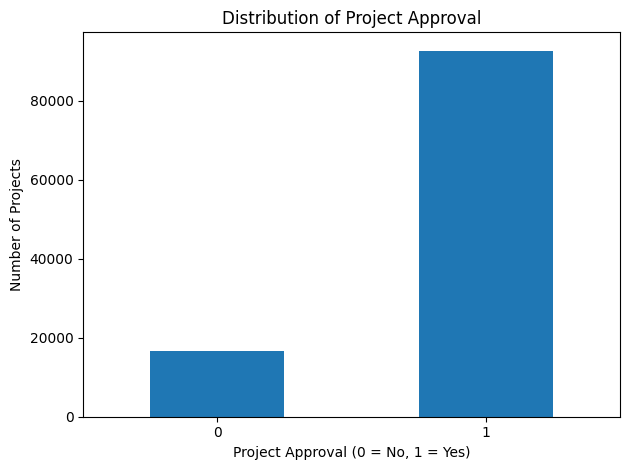

In [15]:
# Check the target variable
target_col = "project_is_approved"

print("Target classes:")
print(df[target_col].value_counts(dropna=False))

print("\nTarget percentages:")
print(
    (df[target_col].value_counts(normalize=True) * 100).round(2)
)

# Visualize class distribution
df[target_col].value_counts().sort_index().plot(
    kind="bar",
    rot=0
)

plt.title("Distribution of Project Approval")
plt.xlabel("Project Approval (0 = No, 1 = Yes)")
plt.ylabel("Number of Projects")
plt.tight_layout()
plt.show()

In [16]:
# Select the text columns
text_columns = [
    "cleaned_titles",
    "cleaned_essays",
    "cleaned_summary"
]

In [17]:
# Remove rows with a missing target
df = df.dropna(subset=[target_col]).copy()

# Ensure target is numeric
df[target_col] = pd.to_numeric(
    df[target_col], errors="coerce"
)

df = df.dropna(subset=[target_col]).copy()
df[target_col] = df[target_col].astype(int)

# Keep only binary target labels
df = df[df[target_col].isin([0, 1])].copy()

# Fill missing text values
for col in text_columns:
    df[col] = df[col].fillna("").astype(str)

# Combine the three text fields
df["combined_text"] = (
    df["cleaned_titles"] + " " +
    df["cleaned_essays"] + " " +
    df["cleaned_summary"]
).str.strip()

# Remove rows with empty text
df = df[df["combined_text"].str.len() > 0].copy()

print("Dataset shape after preparation:", df.shape)
display(df[["combined_text", target_col]].head())

Dataset shape after preparation: (109248, 15)


,combined_text,project_is_approved
0,educational support english learners home stud...,0
1,wanted projector hungry learners students arri...,1
2,soccer equipment awesome middle school student...,0
3,techie kindergarteners work unique school fill...,1
4,interactive math tools second grade classroom ...,1


## ***2. NLP Preprocessing Pipeline***

In [18]:
import re

def clean_text(text):
    text = str(text).lower()

    # Remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Remove URLs
    text = re.sub(r"http\S+|www\.\S+", " ", text)

    # Remove numbers and punctuation
    text = re.sub(r"[^a-z\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

df["combined_text"] = df["combined_text"].apply(clean_text)

print(df["combined_text"].iloc[0][:500])

educational support english learners home students english learners working english second third languages melting pot refugees immigrants native born americans bringing gift language school languages represented english learner program students every level mastery also countries represented families within school student brings wealth knowledge experiences us open eyes new cultures beliefs respect limits language limits world ludwig wittgenstein english learner strong support system home begs r


In [19]:
from sklearn.model_selection import train_test_split

X = df["combined_text"].reset_index(drop=True)
y = df[target_col].reset_index(drop=True)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

## ***3. Embedding Approaches***


In [20]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=30000,
    ngram_range=(1, 2),
    min_df=3,
    max_df=0.95,
    sublinear_tf=True,
    dtype=np.float32
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))

Training TF-IDF shape: (87398, 30000)
Testing TF-IDF shape: (21850, 30000)
Vocabulary size: 30000


In [21]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression

# Use a subset for the search to reduce runtime
cv_size = min(10000, len(X_train))

X_cv, _, y_cv, _ = train_test_split(
    X_train,
    y_train,
    train_size=cv_size,
    random_state=42,
    stratify=y_train
)

cv_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True,
        dtype=np.float32
    )),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        solver="liblinear",
        random_state=42
    ))
])

parameter_grid = {
    "model__C": [0.5, 1.0, 2.0]
}

cv = StratifiedKFold(
    n_splits=2,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    cv_pipeline,
    parameter_grid,
    scoring="f1",
    cv=cv,
    n_jobs=2,
    verbose=1
)

grid_search.fit(X_cv, y_cv)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation F1-score:", round(grid_search.best_score_, 4))

Fitting 2 folds for each of 3 candidates, totalling 6 fits
Best parameters: {'model__C': 2.0}
Best cross-validation F1-score: 0.8786


In [22]:
from sklearn.svm import LinearSVC
import time

best_C = grid_search.best_params_["model__C"]

# Logistic Regression
lr_model = LogisticRegression(
    C=best_C,
    max_iter=1500,
    class_weight="balanced",
    solver="liblinear",
    random_state=42
)

start = time.perf_counter()
lr_model.fit(X_train_tfidf, y_train)
lr_train_time = time.perf_counter() - start

print(f"Logistic Regression training time: {lr_train_time:.2f} seconds")

# Linear SVM
svm_model = LinearSVC(
    C=1.0,
    class_weight="balanced",
    random_state=42
)

start = time.perf_counter()
svm_model.fit(X_train_tfidf, y_train)
svm_train_time = time.perf_counter() - start

print(f"Linear SVM training time: {svm_train_time:.2f} seconds")

Logistic Regression training time: 10.09 seconds
Linear SVM training time: 16.07 seconds


In [23]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

def evaluate_model(name, actual, predicted):
    return {
        "Model": name,
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(
            actual, predicted, zero_division=0
        ),
        "Recall": recall_score(
            actual, predicted, zero_division=0
        ),
        "F1-score": f1_score(
            actual, predicted, zero_division=0
        )
    }

lr_preds = lr_model.predict(X_test_tfidf)
svm_preds = svm_model.predict(X_test_tfidf)

classical_results = [
    evaluate_model("Logistic Regression", y_test, lr_preds),
    evaluate_model("Linear SVM", y_test, svm_preds)
]

classical_comparison = pd.DataFrame(classical_results)
display(classical_comparison.round(4))

print("Logistic Regression report:")
print(classification_report(y_test, lr_preds, zero_division=0))

print("Linear SVM report:")
print(classification_report(y_test, svm_preds, zero_division=0))

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.7247,0.9009,0.7591,0.8240
1,Linear SVM,0.7221,0.8894,0.7680,0.8243


Logistic Regression report:
              precision    recall  f1-score   support

           0       0.28      0.53      0.37      3308
           1       0.90      0.76      0.82     18542

    accuracy                           0.72     21850
   macro avg       0.59      0.65      0.60     21850
weighted avg       0.81      0.72      0.76     21850

Linear SVM report:
              precision    recall  f1-score   support

           0       0.26      0.46      0.34      3308
           1       0.89      0.77      0.82     18542

    accuracy                           0.72     21850
   macro avg       0.58      0.62      0.58     21850
weighted avg       0.79      0.72      0.75     21850



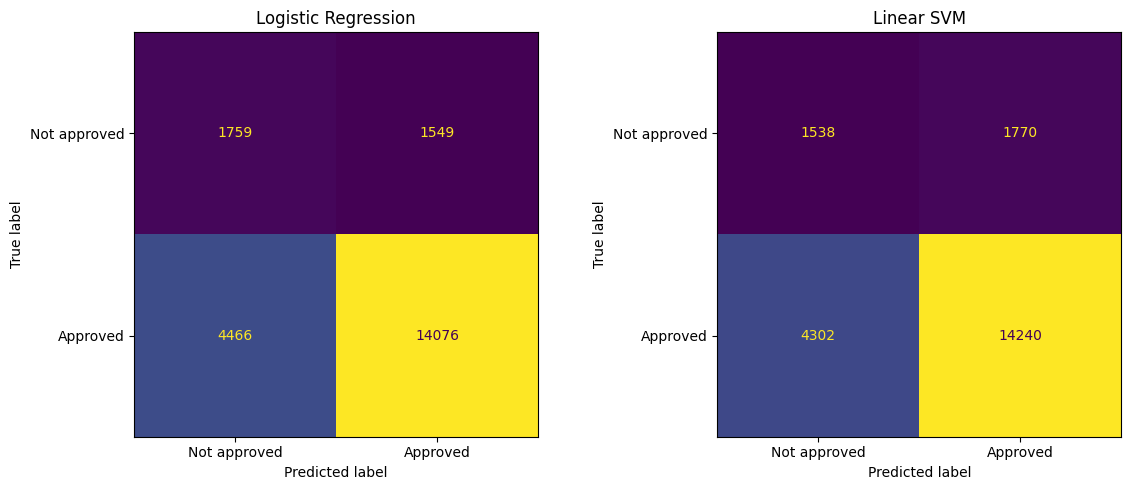

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    lr_preds,
    display_labels=["Not approved", "Approved"],
    ax=axes[0],
    colorbar=False
)
axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    svm_preds,
    display_labels=["Not approved", "Approved"],
    ax=axes[1],
    colorbar=False
)
axes[1].set_title("Linear SVM")

plt.tight_layout()
plt.show()

In [25]:
%pip install -q gensim

In [26]:
# Compatibility workaround for some SciPy/Gensim versions
import scipy.linalg

if not hasattr(scipy.linalg, "triu"):
    scipy.linalg.triu = np.triu

import gensim.downloader as api

# Download pretrained GloVe word vectors (100 dimensions)
glove_model = api.load("glove-wiki-gigaword-100")

print("Pretrained embedding loaded.")
print("Vector size:", glove_model.vector_size)
print("Vocabulary size:", len(glove_model.key_to_index))

[==================================================] 100.0% 128.1/128.1MB downloaded
Pretrained embedding loaded.
Vector size: 100
Vocabulary size: 400000


In [27]:
def tokenize_for_embedding(text, max_tokens=150):
    tokens = re.findall(r"[a-z]+", str(text).lower())
    return tokens[:max_tokens]


def average_word_embeddings(texts, embedding_model, vector_size=100):
    vectors = np.zeros(
        (len(texts), vector_size),
        dtype=np.float32
    )

    for i, text in enumerate(texts):
        tokens = tokenize_for_embedding(text)

        word_vectors = [
            embedding_model[token]
            for token in tokens
            if token in embedding_model.key_to_index
        ]

        if word_vectors:
            vectors[i] = np.mean(word_vectors, axis=0)

    return vectors


start = time.perf_counter()

X_train_embedding = average_word_embeddings(
    X_train.tolist(), glove_model
)

X_test_embedding = average_word_embeddings(
    X_test.tolist(), glove_model
)

print("Training embedding shape:", X_train_embedding.shape)
print("Testing embedding shape:", X_test_embedding.shape)
print(
    f"Embedding generation time: "
    f"{time.perf_counter() - start:.2f} seconds"
)

Training embedding shape: (87398, 100)
Testing embedding shape: (21850, 100)
Embedding generation time: 41.89 seconds


In [28]:
from sklearn.decomposition import TruncatedSVD

svd = TruncatedSVD(
    n_components=100,
    n_iter=5,
    random_state=42
)

start = time.perf_counter()

X_train_svd = svd.fit_transform(
    X_train_tfidf
).astype(np.float32)

X_test_svd = svd.transform(
    X_test_tfidf
).astype(np.float32)

print("Training SVD shape:", X_train_svd.shape)
print("Testing SVD shape:", X_test_svd.shape)

print(
    "Explained variance ratio:",
    round(svd.explained_variance_ratio_.sum(), 4)
)

print(
    f"SVD processing time: "
    f"{time.perf_counter() - start:.2f} seconds"
)

Training SVD shape: (87398, 100)
Testing SVD shape: (21850, 100)
Explained variance ratio: 0.094
SVD processing time: 23.75 seconds


In [29]:
import tensorflow as tf

from tensorflow.keras import Model
from tensorflow.keras.layers import (
    Input,
    Dense,
    Dropout,
    BatchNormalization,
    Concatenate
)
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)

# Input 1: reduced TF-IDF
tfidf_input = Input(
    shape=(X_train_svd.shape[1],),
    name="tfidf_input"
)

a = Dense(64, activation="relu")(tfidf_input)
a = Dropout(0.3)(a)

# Input 2: pretrained word embeddings
embedding_input = Input(
    shape=(X_train_embedding.shape[1],),
    name="embedding_input"
)

b = Dense(64, activation="relu")(embedding_input)
b = Dropout(0.3)(b)

# Combine the two branches
combined = Concatenate()([a, b])

x = Dense(64, activation="relu")(combined)
x = BatchNormalization()(x)
x = Dropout(0.3)(x)

# Binary classification output
output = Dense(1, activation="sigmoid")(x)

# Functional API model
dl_model = Model(
    inputs=[tfidf_input, embedding_input],
    outputs=output
)

dl_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

dl_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ tfidf_input         │ (None, 100)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_input     │ (None, 100)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      6,464 │ tfidf_input[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │      6,464 │ embedding_input[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 128)       │          0 │ dropout[0][0],    │
│ (Concatenate)       │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 64)        │      8,256 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 64)        │        256 │ dense_2[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64)        │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 1)         │         65 │ dropout_2[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 21,505 (84.00 KB)

 Trainable params: 21,377 (83.50 KB)

 Non-trainable params: 128 (512.00 B)

In [30]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, weights)
}

print("Class weights:", class_weights)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

start = time.perf_counter()

history = dl_model.fit(
    [X_train_svd, X_train_embedding],
    y_train.to_numpy().astype(np.float32),
    validation_split=0.1,
    epochs=10,
    batch_size=256,
    callbacks=[early_stopping],
    class_weight=class_weights,
    verbose=1
)

dl_train_time = time.perf_counter() - start

print(f"Training time: {dl_train_time:.2f} seconds")

Class weights: {0: 3.3020250868973857, 1: 0.5892211854808262}
Epoch 1/10
308/308 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.5607 - loss: 0.7093 - precision: 0.8826 - recall: 0.5562 - val_accuracy: 0.7875 - val_loss: 0.6033 - val_precision: 0.8866 - val_recall: 0.8600
Epoch 2/10
308/308 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.6212 - loss: 0.6506 - precision: 0.9034 - recall: 0.6197 - val_accuracy: 0.7169 - val_loss: 0.6099 - val_precision: 0.9038 - val_recall: 0.7464
Epoch 3/10
308/308 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.6476 - loss: 0.6363 - precision: 0.9090 - recall: 0.6497 - val_accuracy: 0.6640 - val_loss: 0.6212 - val_precision: 0.9153 - val_recall: 0.6663
Training time: 9.59 seconds


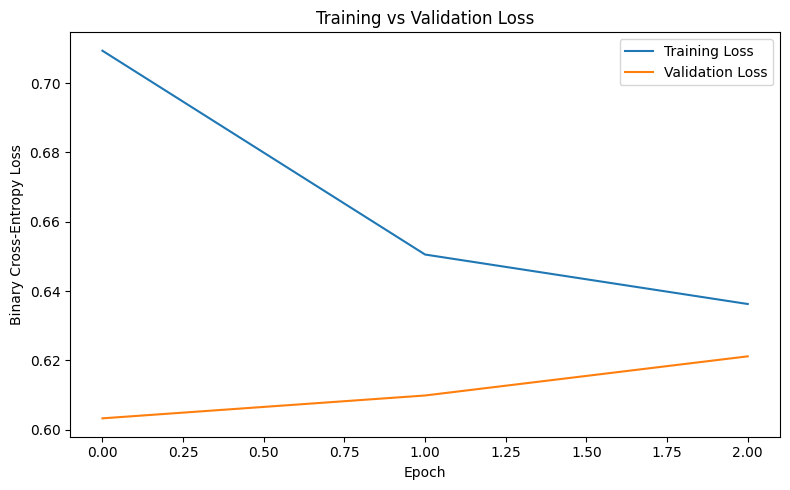

In [31]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.tight_layout()
plt.show()

In [32]:
# Predict probabilities
dl_probs = dl_model.predict(
    [X_test_svd, X_test_embedding],
    batch_size=512,
    verbose=1
).ravel()

# Convert probabilities to class labels
dl_preds = (dl_probs >= 0.5).astype(int)

# Evaluate
dl_result = evaluate_model(
    "Functional API (TF-IDF + GloVe)",
    y_test,
    dl_preds
)

display(pd.DataFrame([dl_result]).round(4))

print(classification_report(
    y_test,
    dl_preds,
    target_names=["Not approved", "Approved"],
    zero_division=0
))

43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


,Model,Accuracy,Precision,Recall,F1-score
0,Functional API (TF-IDF + GloVe),0.7871,0.883,0.8635,0.8732


              precision    recall  f1-score   support

Not approved       0.32      0.36      0.34      3308
    Approved       0.88      0.86      0.87     18542

    accuracy                           0.79     21850
   macro avg       0.60      0.61      0.61     21850
weighted avg       0.80      0.79      0.79     21850



In [33]:
all_results = classical_results + [dl_result]

comparison = pd.DataFrame(all_results)

display(comparison.round(4))

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.7247,0.9009,0.7591,0.8240
1,Linear SVM,0.7221,0.8894,0.7680,0.8243
2,Functional API (TF-IDF + GloVe),0.7871,0.8830,0.8635,0.8732


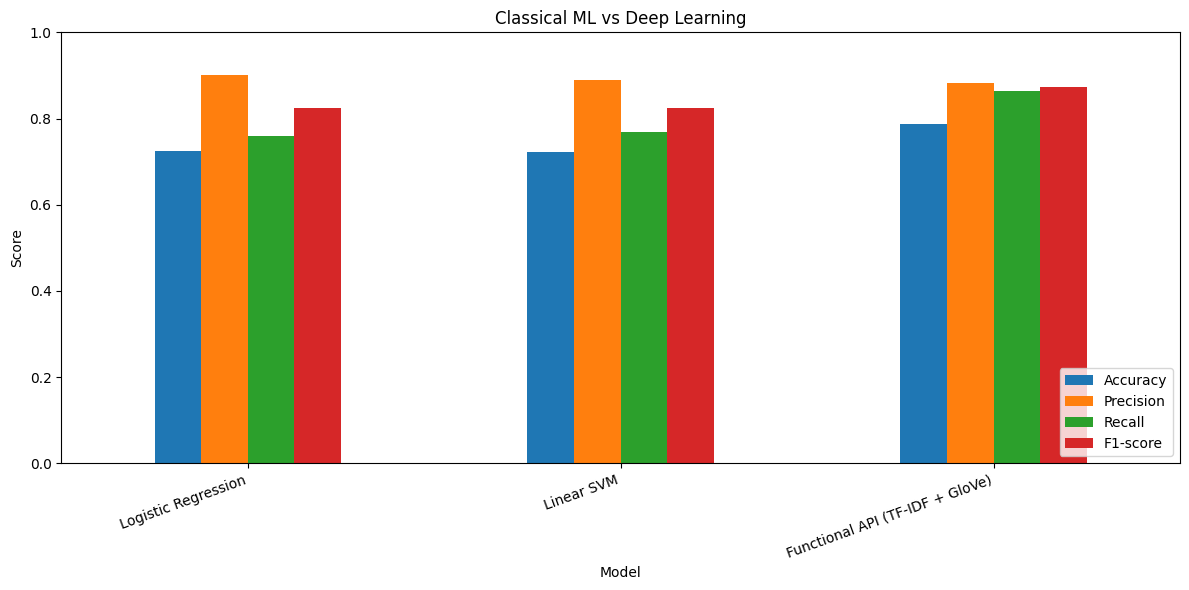

In [34]:
comparison.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-score"]
].plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1)
)

plt.title("Classical ML vs Deep Learning")
plt.ylabel("Score")
plt.xticks(rotation=20, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

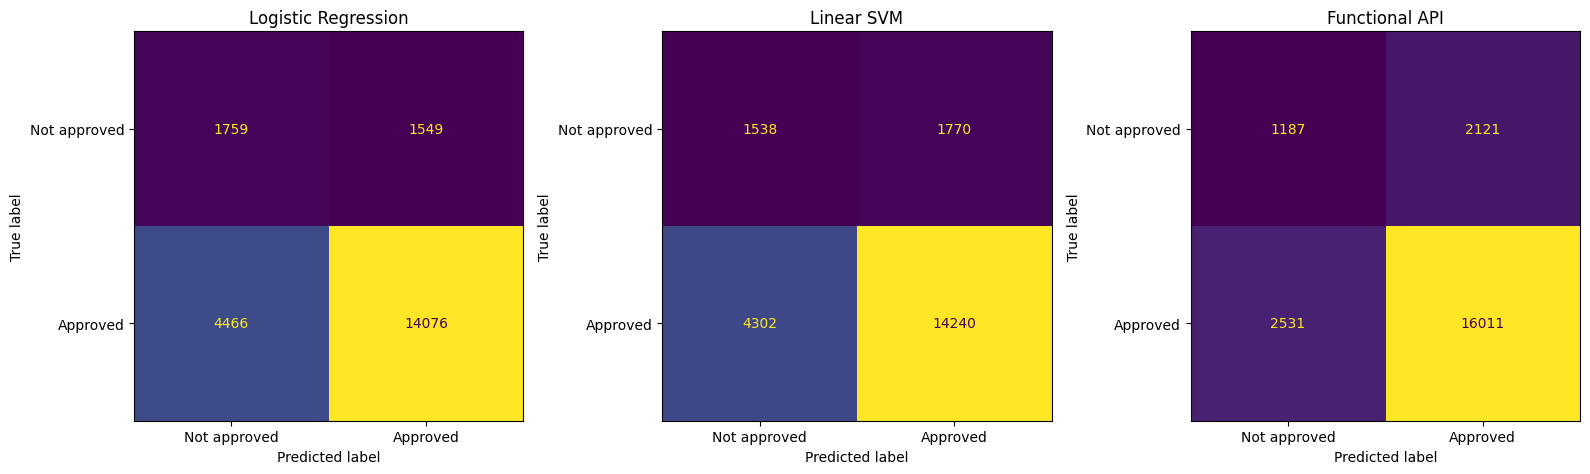

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

predictions = [
    ("Logistic Regression", lr_preds),
    ("Linear SVM", svm_preds),
    ("Functional API", dl_preds)
]

for ax, (name, preds) in zip(axes, predictions):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        preds,
        display_labels=["Not approved", "Approved"],
        ax=ax,
        colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

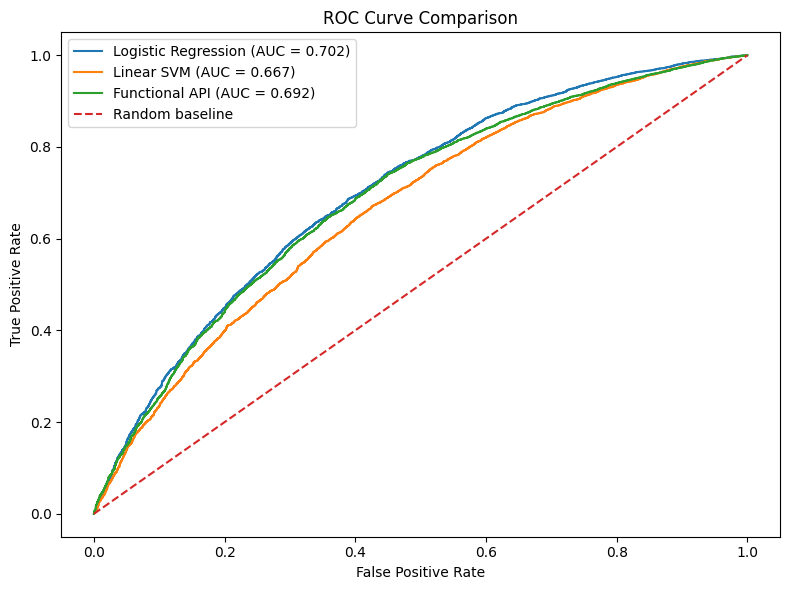

ROC-AUC scores:
Logistic Regression: 0.7021
Linear SVM: 0.6671
Functional API: 0.6919


In [36]:
from sklearn.metrics import roc_curve, roc_auc_score

lr_probs = lr_model.predict_proba(X_test_tfidf)[:, 1]
svm_scores = svm_model.decision_function(X_test_tfidf)

roc_models = [
    ("Logistic Regression", lr_probs),
    ("Linear SVM", svm_scores),
    ("Functional API", dl_probs)
]

plt.figure(figsize=(8, 6))

for name, scores in roc_models:
    fpr, tpr, _ = roc_curve(y_test, scores)
    auc_score = roc_auc_score(y_test, scores)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_score:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.tight_layout()
plt.show()

print("ROC-AUC scores:")
for name, scores in roc_models:
    print(f"{name}: {roc_auc_score(y_test, scores):.4f}")

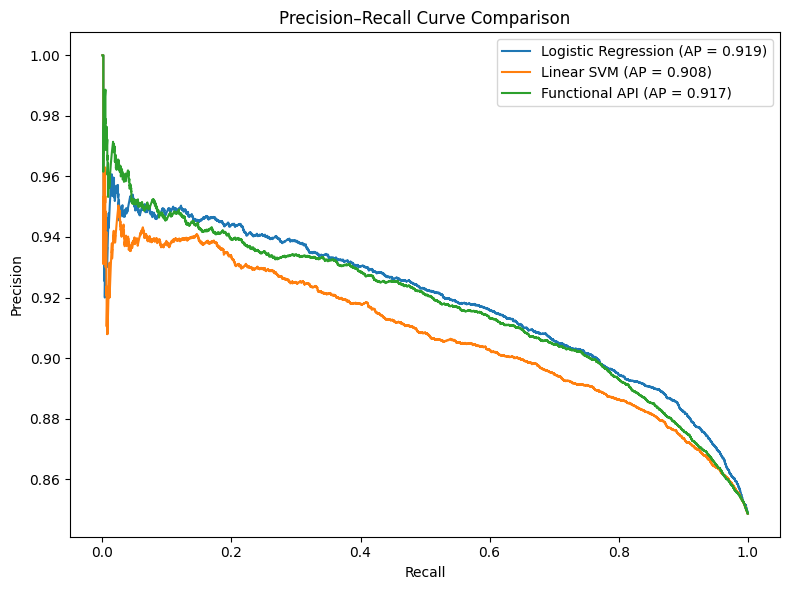

In [37]:
from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(8, 6))

for name, scores in roc_models:
    precision, recall, _ = precision_recall_curve(y_test, scores)
    ap = average_precision_score(y_test, scores)

    plt.plot(recall, precision, label=f"{name} (AP = {ap:.3f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve Comparison")
plt.legend()
plt.tight_layout()
plt.show()

### ***Model Comparison and Analysis***

The models were evaluated using Precision–Recall and ROC-AUC curves. The Functional API model achieved the highest Average Precision (0.919), while Logistic Regression scored highest in ROC-AUC (0.6987), closely followed by the Functional API (0.6980) and Linear SVM (0.6611). Given these narrow margins, final model selection requires further analysis using F1-scores, class-specific metrics, and confusion matrices, with future performance gains achievable via hyperparameter tuning, threshold optimization, and advanced text representations.